In [5]:
import os
from typing import Literal
from langgraph.checkpoint.memory import MemorySaver
from deepagents import create_deep_agent
from tavily import TavilyClient
from dotenv import load_dotenv
from langchain_groq import ChatGroq



In [ ]:
load_dotenv()

os.environ["LANGCHAIN_TRACING_V2"] = "true"
os.environ["LANGCHAIN_API_KEY"] = os.getenv("LANGSMITH_API_KEY")
os.environ["LANGCHAIN_PROJECT"] = os.getenv("LANGSMITH_PROJECT")

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")



llm = ChatOllama(model="gemma2:2b")


In [8]:
llm.invoke("hello")

AIMessage(content='Hello! 👋  \n\nHow can I help you today? 😄 \n', additional_kwargs={}, response_metadata={'model': 'gemma2:2b', 'created_at': '2026-10-22T18:54:40.1399432Z', 'done': True, 'done_reason': 'stop', 'total_duration': 497631900, 'load_duration': 125420400, 'prompt_eval_count': 10, 'prompt_eval_duration': 214042600, 'eval_count': 16, 'eval_duration': 142433200, 'logprobs': None, 'model_name': 'gemma2:2b', 'model_provider': 'ollama'}, id='lc_run--01a164f7-2018-7b32-946f-7af51fca4ca0-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 10, 'output_tokens': 16, 'total_tokens': 26})

In [9]:
tavily_client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])

def internet_search(
    query: str,
    max_results: int = 5,
    topic: Literal["general", "news", "finance"] = "general",
    include_raw_content: bool = False,
):
    """Run a web search"""
    return tavily_client.search(
        query,
        max_results=max_results,
        include_raw_content=include_raw_content,
        topic=topic,
    )

In [10]:
# 1. Instantiate the sub-agent
research_subagent = create_deep_agent(
    name="research-agent",
    system_prompt="You are a great researcher. Use the internet_search tool to gather in-depth information.",
    tools=[internet_search]
)

# 2. Instantiate the supervisor

C:\Users\Malik\AppData\Local\Temp\ipykernel_26356\4168205878.py:2: LangChainDeprecationWarning: Passing `model=None` to `create_deep_agent` is deprecated and will be removed in deepagents==1.0.0. The `model` parameter type will change from `BaseChatModel | str | None` to `BaseChatModel | str`. Specify a model explicitly (e.g., `ChatAnthropic(model_name=...)`). See https://docs.langchain.com/oss/python/deepagents/models
  research_subagent = create_deep_agent(


In [11]:
agent = create_deep_agent(
    name="Supervisor",
    system_prompt="You are the orchestrator. If a user asks for current information or internet searches, route the task to the research-agent.",
    model=llm,
    subagents=[research_subagent],
    checkpointer=MemorySaver() 
)



TypeError: argument of type 'CompiledStateGraph' is not a container or iterable

In [32]:
research_subagent = {
    "name": "research-agent",
    "description": "Used to research more in depth questions",
    "system_prompt": "You are a great researcher",
    "tools": [internet_search],
    "model": llm,  # Optional override, defaults to main agent model
}


In [33]:
subagents = [research_subagent]

agent = create_deep_agent(
    model=llm,
    subagents=subagents
)

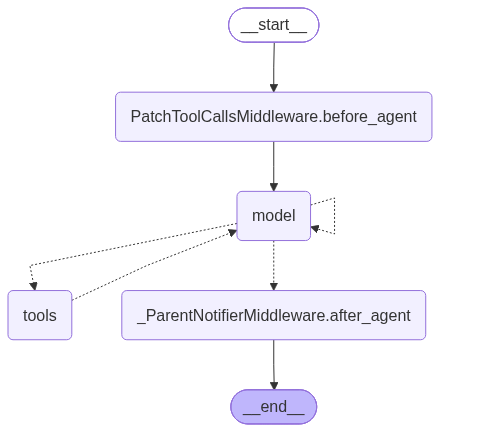

In [12]:
agent

In [36]:
agent.invoke({"role":"user","content":"what is the finance stretagy of the open ai now a days give me the answer form the internet "})

{'messages': [AIMessage(content='How can I help you today?', additional_kwargs={'reasoning_content': "The user hasn't asked anything yet. We need to wait for user query."}, response_metadata={'token_usage': {'completion_tokens': 32, 'prompt_tokens': 1911, 'total_tokens': 1943, 'completion_time': 0.06679615, 'completion_tokens_details': {'reasoning_tokens': 16}, 'prompt_time': 0.094551981, 'prompt_tokens_details': None, 'queue_time': 0.247781268, 'total_time': 0.161348131}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_e1a78f200e', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a164e5-e570-7e53-be8a-b6a28871ef15-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1911, 'output_tokens': 32, 'total_tokens': 1943, 'output_token_details': {'reasoning': 16}})],
 'files': {}}

In [34]:


agent.invoke({"role":"user","content":"search the best  finance stretagy to achive the highest sales on internet "})

{'messages': [AIMessage(content='', additional_kwargs={'reasoning_content': "We need to answer user request. But we haven't seen the user request yet. Let's see next.", 'tool_calls': [{'id': 'fc_09f4e1d6-80d3-434a-9a12-f170159abd31', 'function': {'arguments': '{"path":"/"}', 'name': 'ls'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 44, 'prompt_tokens': 1911, 'total_tokens': 1955, 'completion_time': 0.092442333, 'completion_tokens_details': {'reasoning_tokens': 21}, 'prompt_time': 0.132646588, 'prompt_tokens_details': None, 'queue_time': 0.37670864, 'total_time': 0.225088921}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_4a7bb72c24', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a164e4-aeeb-7272-a2f7-6e23f0ef484a-0', tool_calls=[{'name': 'ls', 'args': {'path': '/'}, 'id': 'fc_09f4e1d6-80d3-434a-9a12-f170159abd31', 'type': 'tool_call'}], invalid_tool_calls=[], us

In [ ]:


agent.invoke({"role":"user","content":"search the best  finance stretagy to achive the highest sales on internet "})

In [3]:
import os
from typing import Literal
from langgraph.checkpoint.memory import MemorySaver
from deepagents import create_deep_agent
from tavily import TavilyClient
from langchain_ollama import  ChatOllama


In [12]:





# Securely load the API key from the environment
tavily_client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])

def internet_search(
    query: str,
    max_results: int = 5,
    topic: Literal["general", "news", "finance"] = "general",
    include_raw_content: bool = False,
):
    """Run a web search"""
    return tavily_client.search(
        query,
        max_results=max_results,
        include_raw_content=include_raw_content,
        topic=topic,
    )

# 1. Define the sub-agent as a configuration dictionary
research_subagent = {
    "name": "research-agent",
    "description": "Used to research current events and internet queries.",
    "system_prompt": "You are a great researcher. Use the internet_search tool to gather accurate information.",
    "tools": [internet_search]
}

# 2. Instantiate the supervisor, passing the dictionary in the subagents list
agent = create_deep_agent(
    model=llm,
    system_prompt="You are the orchestrator. Route tasks requiring internet searches to the research-agent.",
    subagents=[research_subagent],
    checkpointer=MemorySaver() # Required for thread state persistence 
) 

# 3. Configure the thread ID for the checkpointer
thread_config = {"configurable": {"thread_id": "openai_finance_research_01"}}

# 4. Invoke using the standard LangGraph messages schema, not a raw dictionary
response = agent.invoke(
    {"messages": [("user", "what is the finance stretagy of the open ai now a days give me the answer form the internet ")]},
    config=thread_config
)

# Output the final response content
print(response["messages"][-1].content)

ResponseError: registry.ollama.ai/library/gemma2:2b does not support tools (status code: 400)

In [1]:
!pip install  langchain-ollama

  Using cached langchain_ollama-1.1.0-py3-none-any.whl.metadata (3.0 kB)
Using cached langchain_ollama-1.1.0-py3-none-any.whl (31 kB)

   -------------------- ------------------- 1/2 [langchain-ollama]
   ---------------------------------------- 2/2 [langchain-ollama]




[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
